<a href="https://colab.research.google.com/github/Miiixy/GS02-Citizen-assist-AI/blob/main/Citizen_Assist_AI_SERS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **GLOBAL SOLUTION – CITIZEN ASSIST AI**

**Energia Inteligente: Economia e Sustentabilidade nas Residências**

**Disciplina:** Soluções em Energias Renováveis e Sustentáveis

**Turma: 1CCA - Diurno**

**Projeto:** Global Solution 02


## **Grupo:**


Giulliana Maistro  Brasolin - RM 569381

Lara Dos Santos Cândido Alves - RM 573827

Mikaella Mirela Dos Santos Lucindo - RM 573775

---

In [ ]:
# Importações.

import pandas	as	pd
import matplotlib.pyplot as plt

## **Etapa 1 — Contextualização e definição do problema**

### **1A) Apresentação do tema**


O projeto aborda o consumo de energia elétrica nas residências e a importância de adotar alternativas que contribuam para a redução dos gastos e para a sustentabilidade.

A proposta é utilizar análise de dados para avaliar o consumo de uma residência hipotética e comparar soluções que possam melhorar sua eficiência energética.

### **1B) Definição do público-alvo**

O projeto é direcionado a moradores de residências no município de São Paulo - SP que desejam compreender seu consumo de energia elétrica, reduzir gastos e conhecer alternativas de economia e de fornecimento de energia mais sustentáveis.

### **1C) Caracterização da residência**

Para realizar a análise, definimos uma residência hipotética com as seguintes características:

| Característica | Definição |
|---|---|
| Localização | São Paulo - SP |
| Tipo de imóvel | Casa residencial |
| Número de moradores | 4 pessoas |
| Quartos | 2 |
| Banheiros | 1 |
| Fornecimento de energia | Rede elétrica convencional |

É importante destacar que essa residência é um cenário criado para a simulação. Não representa uma residência real nem uma média oficial de consumo das famílias paulistanas.

Foi escolhida uma casa porque a geração solar fotovoltaica exige área adequada no telhado. Em apartamentos, essa alternativa pode não ser aplicável.

### **1D) Identificação do problema**

O consumo de energia elétrica em uma residência depende de diversos fatores, como a quantidade de equipamentos, sua potência e o tempo de utilização.

Sem conhecer esses fatores, torna-se difícil identificar quais aparelhos representam os maiores gastos e quais mudanças poderiam proporcionar economia.

### **1E) Proposta de solução**

A proposta é desenvolver uma análise computacional do consumo energético da residência hipotética e comparar duas alternativas:
1. Substituição de lâmpadas convencionais por lâmpadas LED (eficiência energética).
2. Instalação de um sistema de geração de energia solar fotovoltaica (fonte renovável).

As alternativas serão comparadas considerando custos, viabilidade e impactos ambientais.

Os resultados serão utilizados pelo módulo de energia do Citizen Assist AI. O assistente mostrará ao cidadão quais aparelhos mais consomem, quanto cada alternativa pode economizar e quais são as limitações dessas estimativas, para apoiar decisões mais conscientes sobre o uso da energia.

## **Etapa 2 — Pesquisa e levantamento de dados**

Nesta etapa, vamos reunir os dados necessários para realizar os cálculos.

### **2A) Identificação das fontes oficiais**

Para o levantamento dos dados, foi utilizada como fonte principal a Secretaria de Meio Ambiente, Infraestrutura e Logística do Estado de São Paulo (SEMIL), por disponibilizar informações sobre o consumo residencial de energia elétrica nos municípios paulistas.

**SEMIL — Secretaria de Meio Ambiente, Infraestrutura e Logística de São Paulo**

- Publicação: Anuário de Energéticos por Municípios do Estado de São Paulo 2025.
- Ano-base: 2024.
- Abrangência: municípios do estado de São Paulo.
- Utilização: obter informações sobre o consumo residencial de energia elétrica e a quantidade de consumidores residenciais no município de São Paulo.

Fonte: https://smastr16.blob.core.windows.net/home/2026/03/Anuario-de-Energeticos-por-Municipios-do-Estado-de-Sao-Paulo-2025-ano-base-2024-1.pdf

### **2B) Levantamento do consumo residencial em São Paulo**

In [ ]:
consumo_res_sp_kwh = 12_700_203_908
consumidores_res_sp = 5_100_843

media_anual = consumo_res_sp_kwh / consumidores_res_sp
media_mensal = media_anual / 12

print(f"Média anual por consumidor residencial: {media_anual:.1f} kWh")
print(f"Média mensal por consumidor residencial: {media_mensal:.1f} kWh")

Média anual por consumidor residencial: 2489.8 kWh
Média mensal por consumidor residencial: 207.5 kWh


Segundo a SEMIL (Anuário de Energéticos por Município 2025, ano-base 2024), o município de São Paulo teve 5.100.843 consumidores residenciais e consumo residencial de 12.700.203.908 kWh em 2024. Isso resulta em uma média aproximada de 207,5 kWh por mês por consumidor residencial.

Esse valor é uma média por unidade consumidora e não representa o consumo de uma família específica. Ele será usado na Etapa 3 como referência para avaliar a residência hipotética.

### **2C) Identificação dos equipamentos**

Para estimar o consumo energético da residência, serão considerados inicialmente os seguintes equipamentos:


| Equipamento | Quantidade |
|---|---:|
| Geladeira | 1 |
| Televisão | 1 |
| Chuveiro elétrico | 1 |
| Máquina de lavar | 1 |
| Micro-ondas | 1 |
| Ventiladores | 2 |
| Lâmpadas convencionais | 8 |

### **2D) Potência dos equipamentos**

Para estimar o consumo de energia elétrica da residência, foram atribuídos valores aproximados de potência aos equipamentos identificados no item anterior (2C).

Esses valores são estimativas de referência, pois a potência real pode variar conforme a marca, o modelo e as especificações técnicas de cada aparelho.

**Atenção:** a quantidade de equipamentos faz parte do cenário fictício da residência, e as potências são estimativas do grupo. Nenhum desses valores foi medido nem retirado de especificações de aparelhos reais.

**Lâmpadas convencionais:** neste trabalho, são lâmpadas de 60 W usadas como referência de comparação com lâmpadas LED de 9 W, consideradas de iluminação equivalente.

**Fator de funcionamento da geladeira:** o compressor não opera em potência máxima o tempo todo. Por isso, adotou-se o fator estimado de 0,35 sobre as 24 horas de uso, valor definido pelo grupo e aplicado na Etapa 3.

### **2E) Tempo de utilização dos equipamentos**

Para estimar o consumo mensal de energia elétrica, é necessário definir o tempo médio de utilização diária de cada equipamento e a quantidade de dias de uso durante o mês.

Como a residência analisada é hipotética, foram estabelecidas estimativas de utilização considerando uma família de quatro pessoas. Os valores representam uma situação simulada e não medições reais de uma residência.

**Período de referência:** os cálculos consideram um mês típico de 30 dias, e o consumo anual é obtido multiplicando o consumo mensal por 12. Já a média do município, da SEMIL, refere-se ao ano de 2024.

### **2F) Organização e justificativa dos dados**

Nesta etapa, os dados levantados foram organizados em uma única tabela, reunindo a quantidade, a potência e o tempo estimado de utilização dos equipamentos da residência.

Os dados de potência e utilização são estimativas utilizadas para construir o cenário hipotético. Portanto, os resultados obtidos nas próximas etapas representarão uma simulação, e não o consumo medido de uma residência real.

As unidades utilizadas são watts (W) para potência, horas (h) para tempo de utilização e dias para frequência mensal de uso.

In [ ]:
df_dados = pd.DataFrame({
    "Equipamento": [
        "Geladeira",
        "Televisão",
        "Chuveiro elétrico",
        "Máquina de lavar",
        "Micro-ondas",
        "Ventiladores",
        "Lâmpadas convencionais"
    ],
    "Quantidade": [1, 1, 1, 1, 1, 2, 8],
    "Potência (W)": [150, 100, 5500, 500, 1400, 80, 60],
    "Horas por dia": [24, 5, 1.2, 1, 0.3, 8, 5],
    "Dias por mês": [30, 30, 30, 12, 30, 30, 30],
    "Tipo de dado": ["Estimativa"] * 7
})

display(df_dados)

,Equipamento,Quantidade,Potência (W),Horas por dia,Dias por mês,Tipo de dado
0,Geladeira,1,150,24.0,30,Estimativa
1,Televisão,1,100,5.0,30,Estimativa
2,Chuveiro elétrico,1,5500,1.2,30,Estimativa
3,Máquina de lavar,1,500,1.0,12,Estimativa
4,Micro-ondas,1,1400,0.3,30,Estimativa
5,Ventiladores,2,80,8.0,30,Estimativa
6,Lâmpadas convencionais,8,60,5.0,30,Estimativa


**Justificativa e limitações dos dados:**

- A quantidade de equipamentos foi definida conforme o cenário hipotético apresentado na Etapa 1.
- As potências são valores estimados de referência e podem variar conforme o modelo dos aparelhos.
- O tempo de utilização foi estimado considerando uma residência com quatro moradores.
- A geladeira foi considerada em funcionamento durante 24 horas por dia, mas isso não significa que seu compressor consuma potência máxima continuamente.
- O consumo real também pode variar conforme hábitos dos moradores, eficiência energética e condições de funcionamento dos equipamentos.

Assim, os dados permitem realizar uma análise comparativa, desde que suas limitações sejam consideradas na interpretação dos resultados.

## **Etapa 3 — Cálculo do consumo energético**



Nesta etapa, serão realizados os cálculos do consumo de energia elétrica da residência hipotética, utilizando Python para organizar os dados, estimar o consumo dos equipamentos e identificar os principais responsáveis pelos gastos energéticos.

A geladeira recebe um fator de funcionamento de 0,35, que representa a fração do tempo em que o compressor está ligado. É uma estimativa do grupo, apresentada na tabela abaixo.

### **3A) Cálculo do consumo mensal por equipamento**

Nesta etapa, será calculado o consumo mensal estimado de energia elétrica de cada equipamento da residência.

Para isso, serão considerados a quantidade de aparelhos, a potência, o tempo diário de utilização e os dias de uso durante o mês.

A fórmula utilizada será:

Consumo (kWh) = Quantidade × Potência (W) × Horas por dia × Dias por mês ÷ 1.000

O resultado será expresso em quilowatt-hora (kWh), unidade utilizada para medir o consumo de energia elétrica.

In [ ]:
fator_funcionamento = {
    "Geladeira": 0.35
}


df_dados["Fator de funcionamento"] = (
    df_dados["Equipamento"]
    .map(fator_funcionamento)
    .fillna(1)
)

df_dados["Consumo mensal (kWh)"] = (
    df_dados["Quantidade"]
    * df_dados["Potência (W)"]
    * df_dados["Horas por dia"]
    * df_dados["Dias por mês"]
    * df_dados["Fator de funcionamento"]
    / 1000
)

display(df_dados[
    ["Equipamento", "Quantidade", "Potência (W)",
     "Horas por dia", "Dias por mês",
     "Consumo mensal (kWh)"]
].round(2))

,Equipamento,Quantidade,Potência (W),Horas por dia,Dias por mês,Consumo mensal (kWh)
0,Geladeira,1,150,24.0,30,37.8
1,Televisão,1,100,5.0,30,15.0
2,Chuveiro elétrico,1,5500,1.2,30,198.0
3,Máquina de lavar,1,500,1.0,12,6.0
4,Micro-ondas,1,1400,0.3,30,12.6
5,Ventiladores,2,80,8.0,30,38.4
6,Lâmpadas convencionais,8,60,5.0,30,72.0


In [ ]:
consumo_total = df_dados["Consumo mensal (kWh)"].sum()

print(f"Consumo mensal estimado: {consumo_total:.2f} kWh")
print(f"Consumo anual estimado: {consumo_total * 12:.2f} kWh")

Consumo mensal estimado: 379.80 kWh
Consumo anual estimado: 4557.60 kWh


In [ ]:

print(f"Consumo da simulação: {consumo_total:.1f} kWh/mês")
print(f"Diferença: {(consumo_total / media_mensal - 1) * 100:.0f}% acima da média municipal")

Consumo da simulação: 379.8 kWh/mês
Diferença: 83% acima da média municipal


O consumo estimado da residência hipotética é de 379,8 kWh/mês, cerca de 83% acima da média residencial do município de São Paulo (207,5 kWh/mês, SEMIL 2024). Essa diferença é esperada, pois a média municipal reúne domicílios de perfis muito variados, enquanto o cenário simulado considera 4 moradores e uso diário de chuveiro elétrico. Assim, a residência analisada representa um caso de consumo acima da média, e não a família típica paulistana.

### **3B) Análise do consumo por equipamento**

Após calcular o consumo mensal de cada equipamento, será realizada uma análise para identificar quais aparelhos representam as maiores parcelas do consumo total de energia elétrica.

Essa análise permitirá reconhecer os principais responsáveis pelo consumo da residência e identificar oportunidades de economia energética.

In [ ]:
df_dados["Participação (%)"] = (
    df_dados["Consumo mensal (kWh)"] / consumo_total
) * 100

df_analise = df_dados.sort_values(
    by="Consumo mensal (kWh)",
    ascending=False
)

display(
    df_analise[
        ["Equipamento", "Consumo mensal (kWh)", "Participação (%)"]
    ].round(2)
)

,Equipamento,Consumo mensal (kWh),Participação (%)
2,Chuveiro elétrico,198.0,52.13
6,Lâmpadas convencionais,72.0,18.96
5,Ventiladores,38.4,10.11
0,Geladeira,37.8,9.95
1,Televisão,15.0,3.95
4,Micro-ondas,12.6,3.32
3,Máquina de lavar,6.0,1.58


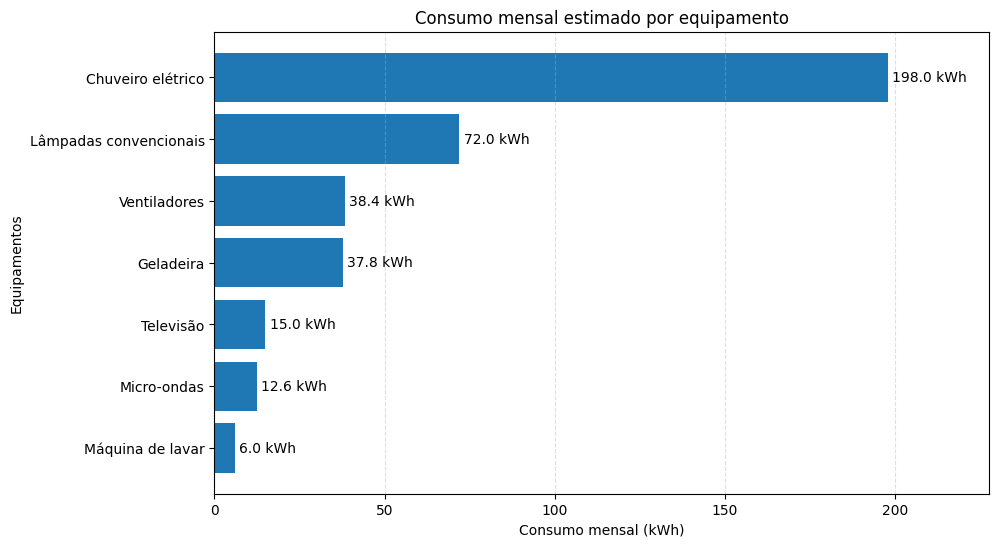

In [ ]:
plt.figure(figsize=(10, 6))

barras = plt.barh(
    df_analise["Equipamento"],
    df_analise["Consumo mensal (kWh)"]
)
plt.bar_label(barras, fmt="%.1f kWh", padding=3)

plt.xlabel("Consumo mensal (kWh)")
plt.ylabel("Equipamentos")
plt.title("Consumo mensal estimado por equipamento")
plt.gca().invert_yaxis()
plt.xlim(0, df_analise["Consumo mensal (kWh)"].max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()

A análise dos resultados permite identificar os equipamentos que apresentam maior participação no consumo mensal de energia elétrica.

Essa identificação é importante para direcionar as medidas de economia, priorizando os equipamentos que possuem maior impacto no consumo total da residência.

Os resultados representam uma simulação baseada nas potências e nos tempos de utilização estimados, podendo variar em uma residência real.

### **3C) Estimativa do custo mensal de energia elétrica**

Com base no consumo mensal estimado na etapa anterior, será calculado o custo aproximado da energia elétrica da residência.

Para essa estimativa, será utilizada a tarifa residencial convencional B1 da Enel São Paulo, vigente entre 4 de julho de 2024 e 3 de julho de 2025, no valor de R$ 0,63624 por kWh.

A escolha dessa tarifa busca manter a análise econômica alinhada ao ano-base de 2024 adotado no projeto.

O cálculo será realizado pela seguinte fórmula:

Custo estimado = Consumo mensal (kWh) × Tarifa (R$/kWh)

In [ ]:
# Tarifa residencial convencional B1 - Enel São Paulo.
# Vigência: 04/07/2024 a 03/07/2025.

tarifa_kwh = 0.63624  # R$/kWh.

custo_mensal = consumo_total * tarifa_kwh
custo_anual = custo_mensal * 12

print(f"Consumo mensal: {consumo_total:.2f} kWh")
print(f"Tarifa considerada: R$ {tarifa_kwh:.5f}/kWh")
print(f"Custo mensal estimado: R$ {custo_mensal:.2f}")
print(f"Custo anual estimado: R$ {custo_anual:.2f}")

Consumo mensal: 379.80 kWh
Tarifa considerada: R$ 0.63624/kWh
Custo mensal estimado: R$ 241.64
Custo anual estimado: R$ 2899.73


In [ ]:
df_custo = pd.DataFrame({
    "Indicador": [
        "Consumo mensal estimado",
        "Tarifa residencial B1",
        "Custo mensal estimado",
        "Custo anual estimado"
    ],
    "Valor": [
        f"{consumo_total:.2f} kWh",
        f"R$ {tarifa_kwh:.5f}/kWh",
        f"R$ {custo_mensal:.2f}",
        f"R$ {custo_anual:.2f}"
    ]
})

display(df_custo)

,Indicador,Valor
0,Consumo mensal estimado,379.80 kWh
1,Tarifa residencial B1,R$ 0.63624/kWh
2,Custo mensal estimado,R$ 241.64
3,Custo anual estimado,R$ 2899.73


**Limitações da estimativa:**

O valor calculado representa uma estimativa do custo de energia consumida, não o valor final da conta de luz.

Não estão incluídos impostos, bandeiras tarifárias, contribuição de iluminação pública e outros encargos que possam incidir na fatura.

Além disso, o resultado depende das estimativas de potência e tempo de utilização dos equipamentos estabelecidas anteriormente.

Adotou-se como referência única a tarifa vigente após o reajuste de 04/07/2024, pois a tarifa anterior não foi considerada na simulação.

### **3D) Identificação das oportunidades de economia**

Com base na análise do consumo dos equipamentos, foram identificadas oportunidades para reduzir a utilização de energia elétrica na residência.

A identificação considera os equipamentos que apresentam maior participação no consumo mensal e as possibilidades de melhorar sua eficiência energética.

Entre as principais oportunidades estão a redução do tempo de utilização do chuveiro elétrico, a substituição das lâmpadas convencionais por modelos LED e a utilização de equipamentos com maior eficiência energética.

Essas possibilidades serão utilizadas como referência para a escolha e análise das alternativas sustentáveis na próxima etapa.

In [ ]:
df_oportunidades = df_analise[
    ["Equipamento", "Consumo mensal (kWh)", "Participação (%)"]
].copy()

medidas_economia = {
    "Chuveiro elétrico": "Reduzir o tempo de utilização e priorizar banhos mais curtos.",
    "Lâmpadas convencionais": "Substituir por lâmpadas LED de menor potência.",
    "Ventiladores": "Utilizar conforme a necessidade e evitar funcionamento desnecessário.",
    "Geladeira": "Manter a manutenção adequada e evitar abertura frequente da porta."
}

df_oportunidades["Oportunidade de economia"] = (
    df_oportunidades["Equipamento"].map(medidas_economia).fillna("Sem medida prioritária")
)

display(df_oportunidades.round(2))

,Equipamento,Consumo mensal (kWh),Participação (%),Oportunidade de economia
2,Chuveiro elétrico,198.0,52.13,Reduzir o tempo de utilização e priorizar banh...
6,Lâmpadas convencionais,72.0,18.96,Substituir por lâmpadas LED de menor potência.
5,Ventiladores,38.4,10.11,Utilizar conforme a necessidade e evitar funci...
0,Geladeira,37.8,9.95,Manter a manutenção adequada e evitar abertura...
1,Televisão,15.0,3.95,Sem medida prioritária
4,Micro-ondas,12.6,3.32,Sem medida prioritária
3,Máquina de lavar,6.0,1.58,Sem medida prioritária


A análise demonstra que existem diferentes possibilidades de redução do consumo energético.

O chuveiro elétrico merece atenção devido à sua elevada participação no consumo estimado, enquanto as lâmpadas convencionais representam uma oportunidade de melhoria por meio da substituição por modelos LED.

Também existem medidas relacionadas aos hábitos de utilização dos equipamentos, como evitar desperdícios e utilizar os aparelhos de maneira mais eficiente.

A partir dessas oportunidades, foram selecionadas duas alternativas principais para aprofundamento: a eficiência energética por meio da tecnologia LED e a geração de eletricidade por energia solar fotovoltaica.

### **3E) Síntese do diagnóstico energético**

Após a organização dos dados, os cálculos de consumo e a análise dos equipamentos, foi possível estabelecer um diagnóstico energético da residência hipotética.

Nesta etapa, serão reunidos os principais indicadores de consumo e custo, que servirão como referência para avaliar as alternativas sustentáveis apresentadas posteriormente.

In [ ]:
resumo_consumo = pd.DataFrame({
    "Indicador": [
        "Consumo mensal estimado",
        "Consumo anual estimado",
        "Tarifa de energia considerada",
        "Custo mensal estimado",
        "Custo anual estimado"
    ],
    "Resultado": [
        f"{consumo_total:.2f} kWh",
        f"{consumo_total * 12:.2f} kWh",
        f"R$ {tarifa_kwh:.5f}/kWh",
        f"R$ {custo_mensal:.2f}",
        f"R$ {custo_mensal * 12:.2f}"
    ]
})

display(resumo_consumo)

,Indicador,Resultado
0,Consumo mensal estimado,379.80 kWh
1,Consumo anual estimado,4557.60 kWh
2,Tarifa de energia considerada,R$ 0.63624/kWh
3,Custo mensal estimado,R$ 241.64
4,Custo anual estimado,R$ 2899.73


A análise permitiu estimar o consumo mensal e anual de energia elétrica da residência, além de identificar os equipamentos que mais contribuem para a demanda energética.

Os resultados demonstram a importância de compreender os hábitos de consumo e identificar oportunidades de economia.

O consumo e o custo estimados serão utilizados como referência para avaliar as alternativas de eficiência energética e geração de energia renovável.

Todos os resultados representam uma simulação baseada em estimativas de potência e utilização, não medições reais de uma residência.

## **Etapa 4 — Análise e comparação das alternativas sustentáveis**

Agora começamos a comparar as duas soluções do projeto: eficiência energética e geração de energia renovável.

### **4A) Apresentação das alternativas sustentáveis**

Com base no diagnóstico energético realizado na Etapa 3, foram selecionadas duas alternativas para reduzir os custos com energia elétrica e melhorar a sustentabilidade da residência.

A primeira alternativa consiste na substituição das lâmpadas convencionais por modelos LED, promovendo eficiência energética por meio da redução do consumo.

A segunda alternativa consiste na instalação de um sistema de geração solar fotovoltaica conectado à rede elétrica, permitindo produzir eletricidade a partir de uma fonte renovável.

As duas alternativas serão analisadas considerando o consumo energético, os custos de implantação, a economia financeira, a viabilidade e os impactos ambientais.

Também será avaliada a possibilidade de combinar as duas soluções.

In [ ]:
alternativas = pd.DataFrame({
    "Alternativa": [
        "Substituição das lâmpadas por LED",
        "Instalação de sistema solar fotovoltaico"
    ],
    "Categoria": [
        "Eficiência energética",
        "Geração de energia renovável"
    ],
    "Objetivo": [
        "Reduzir o consumo de eletricidade",
        "Gerar eletricidade a partir da luz solar"
    ]
})

display(alternativas)

,Alternativa,Categoria,Objetivo
0,Substituição das lâmpadas por LED,Eficiência energética,Reduzir o consumo de eletricidade
1,Instalação de sistema solar fotovoltaico,Geração de energia renovável,Gerar eletricidade a partir da luz solar


### **4B) Análise da substituição das lâmpadas convencionais por LED**

A primeira alternativa consiste em substituir as oito lâmpadas convencionais de 60 W por lâmpadas LED de 9 W.

A tecnologia LED apresenta menor potência para uma iluminação equivalente, permitindo reduzir o consumo de energia elétrica.

Para realizar a comparação, serão mantidas as mesmas condições de utilização: cinco horas por dia e 30 dias por mês.

Serão calculados o consumo após a substituição, a economia mensal e anual de energia e a redução estimada nos custos.

In [ ]:
quantidade_lampadas = 8
potencia_convencional = 60
potencia_led = 9

horas_por_dia = 5
dias_por_mes = 30


consumo_convencional = (
    quantidade_lampadas
    * potencia_convencional
    * horas_por_dia
    * dias_por_mes
    / 1000
)

consumo_led = (
    quantidade_lampadas
    * potencia_led
    * horas_por_dia
    * dias_por_mes
    / 1000
)


economia_kwh = consumo_convencional - consumo_led

economia_percentual = (
    economia_kwh / consumo_convencional
) * 100

consumo_com_led = consumo_total - economia_kwh

print(f"Consumo convencional: {consumo_convencional:.2f} kWh/mês")
print(f"Consumo com LED: {consumo_led:.2f} kWh/mês")
print(f"Economia mensal: {economia_kwh:.2f} kWh")
print(f"Redução percentual: {economia_percentual:.2f}%")
print(f"Novo consumo residencial: {consumo_com_led:.2f} kWh/mês")

Consumo convencional: 72.00 kWh/mês
Consumo com LED: 10.80 kWh/mês
Economia mensal: 61.20 kWh
Redução percentual: 85.00%
Novo consumo residencial: 318.60 kWh/mês


In [ ]:
economia_financeira_mensal = economia_kwh * tarifa_kwh
economia_financeira_anual = economia_financeira_mensal * 12

print(f"Economia financeira mensal: R$ {economia_financeira_mensal:.2f}")
print(f"Economia financeira anual: R$ {economia_financeira_anual:.2f}")

Economia financeira mensal: R$ 38.94
Economia financeira anual: R$ 467.25


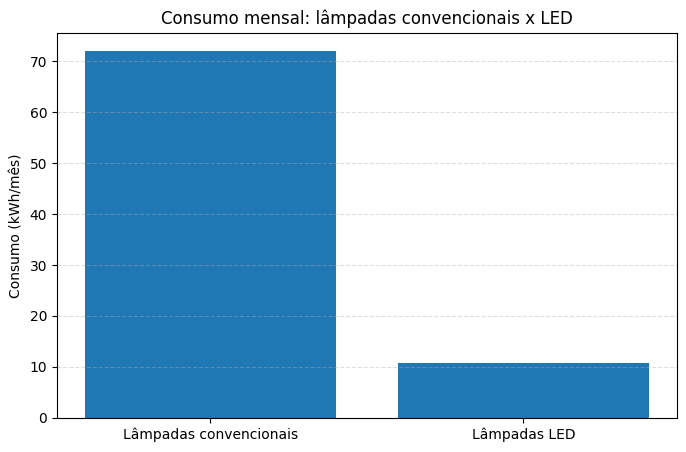

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Lâmpadas convencionais", "Lâmpadas LED"],
    [consumo_convencional, consumo_led]
)

plt.title("Consumo mensal: lâmpadas convencionais x LED")
plt.ylabel("Consumo (kWh/mês)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

A substituição das lâmpadas convencionais por modelos LED proporciona uma redução estimada de 85% no consumo destinado à iluminação.

Essa mudança representa economia de energia e diminuição dos custos mensais da residência.

A alternativa apresenta baixa complexidade de implantação, pois exige apenas a aquisição e instalação das novas lâmpadas.

Entretanto, é necessário considerar o investimento inicial para aquisição dos modelos LED.

Essa solução é classificada como eficiência energética, pois reduz a quantidade de eletricidade necessária para a iluminação, mas não representa geração de energia renovável.

Para fins de simulação, foi considerada a substituição de cada lâmpada convencional de 60 W por uma lâmpada LED de 9 W, assumindo que os modelos escolhidos oferecem níveis de iluminação equivalentes. Essa equivalência deve ser confirmada pelas especificações de fluxo luminoso (lúmens) dos produtos adquiridos. Portanto, a redução calculada representa uma estimativa baseada nessa premissa.

### **4C) Dimensionamento do sistema solar fotovoltaico**

A segunda alternativa consiste na instalação de um sistema solar fotovoltaico conectado à rede elétrica, conhecido como sistema on-grid.

Esse sistema utiliza módulos fotovoltaicos para converter a energia solar em eletricidade, permitindo reduzir a quantidade de energia que precisa ser adquirida da distribuidora.

Para o dimensionamento, será considerado o consumo mensal da residência após a substituição das lâmpadas convencionais por LED.

Será adotada uma produtividade média estimada de 113,5 kWh por kWp instalado ao mês para a simulação em São Paulo.

Essa produtividade é uma hipótese de dimensionamento e deverá ser validada considerando a localização, a orientação dos módulos, o sombreamento e as características do telhado.

In [ ]:
consumo_referencia = consumo_com_led

produtividade_solar = 113.5  # kWh/kWp por mês.

potencia_necessaria = consumo_referencia / produtividade_solar

potencia_sistema = 3.0  # kWp.

quantidade_modulos = 6
potencia_modulo = 500  # Wp.

geracao_solar = potencia_sistema * produtividade_solar

print(f"Consumo mensal de referência: {consumo_referencia:.2f} kWh")
print(f"Potência calculada: {potencia_necessaria:.2f} kWp")
print(f"Potência do sistema escolhido: {potencia_sistema:.2f} kWp")
print(f"Quantidade de módulos: {quantidade_modulos}")
print(f"Potência por módulo: {potencia_modulo} Wp")
print(f"Geração mensal estimada: {geracao_solar:.2f} kWh")

Consumo mensal de referência: 318.60 kWh
Potência calculada: 2.81 kWp
Potência do sistema escolhido: 3.00 kWp
Quantidade de módulos: 6
Potência por módulo: 500 Wp
Geração mensal estimada: 340.50 kWh


In [ ]:
df_solar = pd.DataFrame({
    "Característica": [
        "Tipo de sistema",
        "Potência instalada",
        "Quantidade de módulos",
        "Potência por módulo",
        "Potência do inversor de referência",
        "Geração mensal estimada",
        "Geração anual estimada"
    ],
    "Especificação": [
        "On-grid",
        "3,0 kWp",
        "6 módulos",
        "500 Wp",
        "3 kW",
        f"{geracao_solar:.2f} kWh",
        f"{geracao_solar * 12:.2f} kWh"
    ]
})

display(df_solar)

,Característica,Especificação
0,Tipo de sistema,On-grid
1,Potência instalada,"3,0 kWp"
2,Quantidade de módulos,6 módulos
3,Potência por módulo,500 Wp
4,Potência do inversor de referência,3 kW
5,Geração mensal estimada,340.50 kWh
6,Geração anual estimada,4086.00 kWh


A produtividade solar adotada foi de 113,5 kWh/kWp/mês, obtida a partir da referência anual de 1.362 kWh/kWp apresentada para São Paulo. Com base no consumo de referência de 318,6 kWh/mês, a potência calculada foi de aproximadamente 2,81 kWp. Foi escolhido um sistema de 3,0 kWp, composto por seis módulos de 500 Wp, resultando em uma geração mensal estimada de 340,5 kWh.

O sistema escolhido possui potência ligeiramente superior à necessidade calculada, oferecendo uma margem na estimativa de geração. Entretanto, a produção real depende das condições de instalação, orientação dos módulos, sombreamento, perdas e variações sazonais.

### **4D) Comparação dos resultados das alternativas**

Nesta etapa, serão comparados os resultados das duas alternativas analisadas, considerando a redução do consumo proporcionada pelas lâmpadas LED e a geração média estimada pelo sistema solar fotovoltaico.

Também será apresentado um cenário combinado, no qual as duas soluções são utilizadas simultaneamente.

O objetivo é verificar como as alternativas podem contribuir para reduzir a demanda de energia elétrica da rede convencional.

In [ ]:
df_comparacao_alternativas = pd.DataFrame({
    "Cenário": [
        "Residência original",
        "Substituição por LED",
        "LED + sistema solar"
    ],
    "Consumo mensal (kWh)": [
        consumo_total,
        consumo_com_led,
        consumo_com_led
    ],
    "Geração solar mensal (kWh)": [
        0,
        0,
        geracao_solar
    ]
})

df_comparacao_alternativas["Saldo energético teórico (kWh)"] = (
    df_comparacao_alternativas["Consumo mensal (kWh)"]
    - df_comparacao_alternativas["Geração solar mensal (kWh)"]
)

display(df_comparacao_alternativas.round(2))

,Cenário,Consumo mensal (kWh),Geração solar mensal (kWh),Saldo energético teórico (kWh)
0,Residência original,379.8,0.0,379.8
1,Substituição por LED,318.6,0.0,318.6
2,LED + sistema solar,318.6,340.5,-21.9


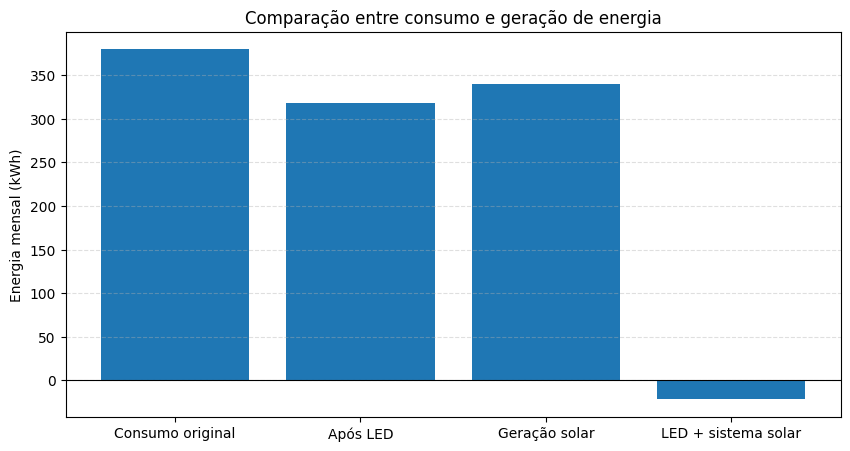

In [ ]:
cenarios = [
    "Consumo original",
    "Após LED",
    "Geração solar",
    "LED + sistema solar"
]

valores = [
    consumo_total,
    consumo_com_led,
    geracao_solar,
    consumo_com_led - geracao_solar
]

plt.figure(figsize=(10, 5))

plt.bar(cenarios, valores)

plt.title("Comparação entre consumo e geração de energia")
plt.ylabel("Energia mensal (kWh)")
plt.axhline(y=0, color="black", linewidth=0.8)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

A comparação demonstra que a substituição das lâmpadas convencionais por modelos LED reduz o consumo mensal estimado da residência.

O sistema fotovoltaico de 3,0 kWp apresenta geração média estimada próxima à demanda energética da residência após a adoção das lâmpadas LED.

Quando combinadas, as duas alternativas podem contribuir para diminuir a dependência da eletricidade fornecida pela distribuidora.

O saldo energético apresentado representa uma comparação matemática entre o consumo estimado após a substituição das lâmpadas por LED (318,6 kWh/mês) e a geração solar média estimada (340,5 kWh/mês).

O saldo negativo de 21,9 kWh/mês indica que a geração média calculada supera o consumo de referência nesse cenário. Entretanto, isso não significa que a residência ficará sem cobrança na conta de luz. A compensação efetiva depende das regras aplicáveis à geração distribuída, das condições de conexão, do consumo em cada período e dos encargos cobrados pela distribuidora.

### **4E) Viabilidade e impactos ambientais das alternativas**

As duas alternativas apresentam benefícios econômicos e ambientais, mas possuem características diferentes de implantação.

A substituição das lâmpadas convencionais por modelos LED apresenta menor complexidade, pois exige apenas a aquisição e instalação das novas lâmpadas. Seu principal benefício é reduzir o consumo de energia elétrica.

Já o sistema solar fotovoltaico exige um investimento inicial maior, avaliação técnica do imóvel e instalação de equipamentos específicos. Em contrapartida, permite gerar eletricidade a partir de uma fonte renovável e reduzir a dependência da energia fornecida pela rede convencional.

Do ponto de vista ambiental, a eficiência energética contribui para reduzir a demanda por eletricidade, enquanto a geração solar utiliza uma fonte renovável e pode diminuir a dependência de fontes convencionais.

Entretanto, ambas as soluções possuem impactos associados à fabricação, transporte e descarte dos equipamentos.

A escolha da alternativa mais adequada depende das condições financeiras, estruturais e energéticas da residência.


In [ ]:
df_viabilidade = pd.DataFrame({
    "Critério": [
        "Investimento inicial",
        "Complexidade de instalação",
        "Redução do consumo da residência",
        "Geração de energia renovável",
        "Necessidade de espaço"
    ],
    "Lâmpadas LED": [
        "Baixo, em comparação ao sistema solar",
        "Baixa",
        "Sim",
        "Não",
        "Não exige espaço adicional relevante"
    ],
    "Sistema solar": [
        "Mais elevado",
        "Exige avaliação e instalação técnica",
        "Não reduz o consumo dos aparelhos",
        "Sim",
        "Exige área adequada no telhado"
    ]
})

display(df_viabilidade)

,Critério,Lâmpadas LED,Sistema solar
0,Investimento inicial,"Baixo, em comparação ao sistema solar",Mais elevado
1,Complexidade de instalação,Baixa,Exige avaliação e instalação técnica
2,Redução do consumo da residência,Sim,Não reduz o consumo dos aparelhos
3,Geração de energia renovável,Não,Sim
4,Necessidade de espaço,Não exige espaço adicional relevante,Exige área adequada no telhado


### **Etapa 4F — Estimativa do investimento, retorno financeiro e impacto ambiental**

Nesta etapa, as alternativas foram comparadas para a mesma necessidade (reduzir o custo de energia da residência de 379,8 kWh/mês), com a mesma tarifa (R$ 0,63624/kWh) e um horizonte comum de 10 anos. Foram analisados: banho 10 minutos mais curto (mudança de hábito), substituição por LED (eficiência energética) e sistema solar fotovoltaico de 3 kWp (fonte renovável).

Preços: LED a R$ 3,23 por unidade (valor de referência adotado como premissa do grupo) e, como cenário de varejo, 12,00 Reais por unidade (premissa do grupo). Sistema fotovoltaico a 2,43/Wp Reais (mercado de São Paulo, 3º trimestre de 2024). Os valores são estimativas e não constituem orçamentos.


Para a análise financeira do sistema fotovoltaico, foi considerado o consumo mensal após a substituição das lâmpadas convencionais por LED, equivalente a 318,6 kWh/mês. Dessa forma, a economia atribuída ao sistema solar é limitada ao consumo de referência, considerando também um cenário simplificado com custo de disponibilidade de 50 kWh/mês.

Para o cenário de redução do tempo de banho, foi considerada uma diminuição total de 10 minutos de utilização diária do chuveiro elétrico na residência. Essa redução é aplicada ao consumo do chuveiro como um todo, e não individualmente para cada morador. Trata-se de uma hipótese simplificada para estimar o potencial de economia.

Nota: Os valores adotados representam estimativas técnicas para fins de modelagem acadêmica e não constituem orçamentos comerciais.

In [ ]:
# Premissas
HORIZONTE_ANOS = 10
FATOR_EMISSAO = 0.0545      # kg CO2/kWh  <-- fator médio anual do SIN (MCTI).
DISPONIBILIDADE = 50        # Hipótese de ligação bifásica: Custo de disponibilidade equivalente a 50 kWh/mês.
preco_led_publico = 3.23    # R$/lâmpada (premissa do grupo).
preco_led_varejo = 12.00    # R$/lâmpada (premissa de varejo).
preco_wp = 2.43             # R$/Wp (São Paulo, 3º tri/2024).

# Investimentos.
investimento_led_publico = quantidade_lampadas * preco_led_publico
investimento_led_varejo = quantidade_lampadas * preco_led_varejo
investimento_solar = potencia_sistema * 1000 * preco_wp

# Economia de energia.
economia_banho_kwh = 5.5 * (10 / 60) * 30  # 10 min a menos por dia.

# Economia solar considerando o consumo após a substituição por LED.
solar_sem_disp = min(geracao_solar, consumo_referencia)

# Cenário simplificado considerando custo de disponibilidade de 50 kWh.
solar_com_disp = min(
    geracao_solar,
    max(0, consumo_referencia - DISPONIBILIDADE)
)

# Tabela comparativa.
def linha(nome, investimento, kwh_mes):
    econ_mes = kwh_mes * tarifa_kwh
    return {
        "Alternativa": nome,
        "Investimento (R$)": investimento,
        "Economia (kWh/mês)": kwh_mes,
        "Economia (R$/mês)": econ_mes,
        "Payback (meses)": investimento / econ_mes if investimento > 0 else 0,
        f"Saldo em {HORIZONTE_ANOS} anos (R$)": econ_mes * 12 * HORIZONTE_ANOS - investimento,
        "CO₂ evitado (kg/ano)": kwh_mes * 12 * FATOR_EMISSAO,
    }

df_final = pd.DataFrame([
    linha("Banho 10 min mais curto (hábito)", 0, economia_banho_kwh),
    linha("LED (preço público)", investimento_led_publico, economia_kwh),
    linha("LED (preço varejo)", investimento_led_varejo, economia_kwh),
    linha("Solar 3 kWp (sem custo de disponibilidade)", investimento_solar, solar_sem_disp),
    linha("Solar 3 kWp (com custo de disponibilidade)", investimento_solar, solar_com_disp),
])

display(df_final.round(1))

payback_solar_anos = df_final.iloc[4]["Payback (meses)"] / 12
print(f"Payback do solar (com custo de disponibilidade): {payback_solar_anos:.1f} anos")

,Alternativa,Investimento (R$),Economia (kWh/mês),Economia (R$/mês),Payback (meses),Saldo em 10 anos (R$),CO₂ evitado (kg/ano)
0,Banho 10 min mais curto (hábito),0.0,27.5,17.5,0.0,2099.6,18.0
1,LED (preço público),25.8,61.2,38.9,0.7,4646.7,40.0
2,LED (preço varejo),96.0,61.2,38.9,2.5,4576.5,40.0
3,Solar 3 kWp (sem custo de disponibilidade),7290.0,318.6,202.7,36.0,17034.7,208.4
4,Solar 3 kWp (com custo de disponibilidade),7290.0,268.6,170.9,42.7,13217.3,175.7


Payback do solar (com custo de disponibilidade): 3.6 anos



#### **Interpretação dos resultados financeiros**

Na mesma base de comparação (consumo original de 379,8 kWh/mês, tarifa de R$ 0,63624/kWh e horizonte de 10 anos), o banho mais curto não exige investimento, o LED tem retorno em poucos meses e o sistema solar exige o maior investimento (7.290,00 Reais), com retorno estimado de 3 a 3,6 anos. O LED e o banho economizam menos energia que o solar, mas com custo muito menor. O solar é a única alternativa que usa fonte renovável e a que mais evita emissões. As alternativas podem ser combinadas.

###**Limitações da estimativa de retorno financeiro**

O payback apresentado representa uma estimativa simplificada do tempo necessário para recuperar o investimento inicial do sistema fotovoltaico.

O cálculo considera uma tarifa constante de R$ 0,63624/kWh e não incorpora integralmente os efeitos da Lei nº 14.300/2022, como a cobrança gradual dos componentes relacionados ao uso da rede elétrica (Fio B), nem possíveis variações tarifárias.

Também não foram incluídos custos de manutenção, substituição do inversor, degradação dos módulos ao longo do tempo, inflação, juros ou alterações futuras no consumo da residência.

Portanto, o retorno calculado deve ser interpretado como uma projeção teórica baseada nas premissas adotadas, e não como uma garantia de retorno financeiro. Uma avaliação real exige orçamento atualizado, análise da unidade consumidora e simulação das regras de compensação aplicáveis.

### **O impacto ambiental**

A rede elétrica brasileira tem fator de emissão relativamente baixo, então o CO₂ evitado por kWh é pequeno em termos absolutos (ver coluna “CO₂ evitado” da tabela). A energia solar evita mais emissões por gerar mais energia, mas a fabricação, o transporte e o descarte dos módulos e do inversor também causam impactos e exigem destinação adequada.

### **Considerações sobre o impacto ambiental**

A estimativa de emissões evitadas foi calculada utilizando o fator médio de emissão de gases de efeito estufa do Sistema Interligado Nacional (SIN), considerando o valor de referência de 0,0545 kg CO₂/kWh.

Esse indicador permite estimar a quantidade de emissões associadas à geração de energia elétrica que poderia ser evitada com a redução do consumo ou com a geração fotovoltaica.

Entretanto, o cálculo não representa uma análise completa do ciclo de vida dos equipamentos. Não foram contabilizadas as emissões relacionadas à fabricação, ao transporte, à instalação e ao descarte dos módulos fotovoltaicos, inversores e lâmpadas.

Assim, os valores apresentados são estimativas de emissões evitadas durante o uso da energia, e não uma avaliação ambiental integral das tecnologias.

### **Limitações**

Os valores são estimativas e não resultados garantidos. O cálculo não inclui tributos (o que tende a subestimar a economia em reais), a cobrança do Fio B prevista na Lei 14.300/2022, manutenção, troca do inversor, degradação dos módulos nem reajustes de tarifa. O preço do LED varia bastante entre compra pública e varejo, e o custo de disponibilidade depende do tipo de ligação. A tarifa adotada é a de 04/07/2024 a 03/07/2025.

## **Etapa 5 — Desenvolvimento e aplicação do Citizen Assist AI**

### **5A) Integração dos resultados ao assistente**

Nesta etapa, os resultados da análise energética serão utilizados para
desenvolver o módulo de orientação do Citizen Assist AI.

O assistente terá como objetivo ajudar moradores a compreender o consumo
de energia elétrica de uma residência, identificar oportunidades de
economia e conhecer alternativas sustentáveis.

As recomendações serão baseadas nos cálculos realizados nas etapas
anteriores, considerando o cenário residencial hipotético de São Paulo.

O protótipo utilizará estruturas condicionais e funções em Python
para interpretar as opções selecionadas pelo usuário e apresentar
orientações relacionadas ao consumo, à eficiência energética e
à geração solar.

#### **Dados utilizados pelo assistente**

O módulo de orientação utilizará os seguintes resultados:

- Consumo original: 379,8 kWh/mês.
- Consumo após substituição por LED: 318,6 kWh/mês.
- Economia com LED: 61,2 kWh/mês.
- Geração solar estimada: 340,5 kWh/mês
- Potência do sistema fotovoltaico: 3 kWp.
- Tarifa de referência: R$ 0,63624/kWh.

Esses valores representam estimativas do cenário hipotético desenvolvido
no projeto e não devem ser interpretados como dados reais de uma
residência específica.

### **5B) Desenvolvimento da lógica de orientação**

### **Versão anterior ao teste:**

In [ ]:
'''RODAPE = "\n(Valores estimados para um cenário hipotético. Digite 6 para ver fontes e limitações.)"

def orientar_usuario(opcao):
    opcao = str(opcao).strip()

    # valores vindos dos cálculos anteriores
    chuveiro = df_analise[df_analise["Equipamento"] == "Chuveiro elétrico"].iloc[0]
    banho = df_final.iloc[0]
    led_pub = df_final.iloc[1]
    led_var = df_final.iloc[2]
    solar_sem = df_final.iloc[3]
    solar_com = df_final.iloc[4]

    if opcao == "1":
        return f"""
DIAGNÓSTICO DE CONSUMO

Consumo estimado da residência: {consumo_total:.1f} kWh/mês
(custo de energia de cerca de R$ {custo_mensal:.2f}/mês, sem tributos).
Isso é {(consumo_total / media_mensal - 1) * 100:.0f}% acima da média residencial
do município de São Paulo ({media_mensal:.1f} kWh/mês).

O chuveiro elétrico é o maior consumidor: {chuveiro["Participação (%)"]:.1f}% do total.
{RODAPE}"""

    elif opcao == "2":
        return f"""
BANHO MAIS CURTO (sem custo)

Reduzir 10 minutos de banho por dia economiza cerca de
{banho["Economia (kWh/mês)"]:.1f} kWh/mês, ou R$ {banho["Economia (R$/mês)"]:.2f}/mês
(sem tributos), sem nenhum investimento.

Recomendação: é uma medida que não exige investimento inicial
e pode reduzir o consumo, embora a economia estimada seja
menor que a obtida com a substituição das lâmpadas por LED.
{RODAPE}"""

    elif opcao == "3":
        return f"""
LÂMPADAS LED

Trocar {quantidade_lampadas} lâmpadas de 60 W por LED de 9 W reduz o consumo de
iluminação em {economia_kwh:.1f} kWh/mês (R$ {led_pub["Economia (R$/mês)"]:.2f}/mês).

Investimento estimado: R$ {led_pub["Investimento (R$)"]:.2f} (preço de compra pública)
a R$ {led_var["Investimento (R$)"]:.2f} (varejo). Retorno de cerca de
{led_pub["Payback (meses)"]:.1f} a {led_var["Payback (meses)"]:.1f} meses.

Recomendação: troca simples e de baixo custo, mas atua em apenas uma
parte pequena do consumo.
{RODAPE}"""

    elif opcao == "4":
        return f"""
ENERGIA SOLAR FOTOVOLTAICA (fonte renovável)

Sistema de {potencia_sistema:.1f} kWp, geração estimada de {geracao_solar:.1f} kWh/mês.
Investimento estimado: R$ {solar_sem["Investimento (R$)"]:.2f}.

Retorno estimado: {solar_sem["Payback (meses)"] / 12:.1f} anos (compensação integral) a
{solar_com["Payback (meses)"] / 12:.1f} anos (descontando o custo de disponibilidade).

A geração varia ao longo do ano e a compensação depende das regras
da distribuidora e da Lei 14.300/2022.

Recomendação: avaliar telhado, sombreamento e orçamentos reais antes de decidir.
{RODAPE}"""

    elif opcao == "5":
        linhas = ""
        for _, r in df_final.iterrows():
            linhas += (f"- {r['Alternativa']}: investimento R$ {r['Investimento (R$)']:.0f}, "
                       f"economia {r['Economia (kWh/mês)']:.1f} kWh/mês, "
                       f"CO2 evitado {r['CO₂ evitado (kg/ano)']:.0f} kg/ano\n")
        return f"""
COMPARAÇÃO DAS ALTERNATIVAS (mesma residência, mesma tarifa, 10 anos)

{linhas}
O banho mais curto e o LED custam pouco e se pagam rápido; o solar exige
mais investimento, mas é a única alternativa com fonte renovável.
As opções podem ser combinadas.
{RODAPE}"""

    elif opcao == "6":
        return f"""
FONTES E LIMITAÇÕES

Fontes: SEMIL (Anuário de Energéticos por Municípios do Estado de SP 2025,
ano-base 2024); EPE (Anuário Estatístico de Energia Elétrica 2025);
ANEEL (Resolução Homologatória nº 3.339/2024, tarifa Enel SP B1,
R$ {tarifa_kwh:.5f}/kWh); CRESESB/PVGIS (irradiação e produtividade solar);
preços de LED e fotovoltaico conforme referências do notebook.

Limitações:
- Potências e horários de uso são estimativas, não medições.
- A tarifa é de 04/07/2024 a 03/07/2025 e não inclui tributos nem bandeiras.
- Retorno do solar não considera Fio B, manutenção, troca do inversor
  nem reajustes de tarifa.
- O assistente é informativo e não substitui avaliação técnica.
"""

    else:
        return "\nOpção inválida. Escolha uma opção do menu (0 a 6).\n"'''

'RODAPE = "\n(Valores estimados para um cenário hipotético. Digite 6 para ver fontes e limitações.)"\n\ndef orientar_usuario(opcao):\n    opcao = str(opcao).strip()\n\n    # valores vindos dos cálculos anteriores\n    chuveiro = df_analise[df_analise["Equipamento"] == "Chuveiro elétrico"].iloc[0]\n    banho = df_final.iloc[0]\n    led_pub = df_final.iloc[1]\n    led_var = df_final.iloc[2]\n    solar_sem = df_final.iloc[3]\n    solar_com = df_final.iloc[4]\n\n    if opcao == "1":\n        return f"""\nDIAGNÓSTICO DE CONSUMO\n\nConsumo estimado da residência: {consumo_total:.1f} kWh/mês\n(custo de energia de cerca de R$ {custo_mensal:.2f}/mês, sem tributos).\nIsso é {(consumo_total / media_mensal - 1) * 100:.0f}% acima da média residencial\ndo município de São Paulo ({media_mensal:.1f} kWh/mês).\n\nO chuveiro elétrico é o maior consumidor: {chuveiro["Participação (%)"]:.1f}% do total.\n{RODAPE}"""\n\n    elif opcao == "2":\n        return f"""\nBANHO MAIS CURTO (sem custo)\n\nReduzir 10 

### **Versão pós teste:**

In [ ]:
RODAPE = "\n(Valores estimados para um cenário hipotético. Digite 6 para ver fontes e limitações.)"

def orientar_usuario(opcao):
    opcao = str(opcao).strip()

    # valores vindos dos cálculos anteriores.
    chuveiro = df_analise[df_analise["Equipamento"] == "Chuveiro elétrico"].iloc[0]
    banho = df_final.iloc[0]
    led_pub = df_final.iloc[1]
    led_var = df_final.iloc[2]
    solar_sem = df_final.iloc[3]
    solar_com = df_final.iloc[4]

    if opcao == "1":
        return f"""
DIAGNÓSTICO DE CONSUMO

Consumo estimado da residência: {consumo_total:.1f} kWh/mês
(kWh = quilowatt-hora, a unidade que aparece na sua conta de luz).
O custo da energia é de cerca de R$ {custo_mensal:.2f}/mês, sem tributos.
Isso é {(consumo_total / media_mensal - 1) * 100:.0f}% acima da média residencial
do município de São Paulo ({media_mensal:.1f} kWh/mês).

O chuveiro elétrico é o maior consumidor: {chuveiro["Participação (%)"]:.1f}% do total.
{RODAPE}"""

    elif opcao == "2":
        return f"""
BANHO MAIS CURTO (sem custo)

Reduzir 10 minutos de banho por dia economiza cerca de
{banho["Economia (kWh/mês)"]:.1f} kWh/mês, ou R$ {banho["Economia (R$/mês)"]:.2f}/mês
(sem tributos), sem nenhum investimento.

Recomendação: é uma medida que não exige investimento inicial
e pode reduzir o consumo, embora a economia estimada seja
menor que a obtida com a substituição das lâmpadas por LED.
{RODAPE}"""

    elif opcao == "3":
        return f"""
LÂMPADAS LED

Trocar {quantidade_lampadas} lâmpadas de 60 W por LED de 9 W reduz o consumo de
iluminação em {economia_kwh:.1f} kWh/mês (R$ {led_pub["Economia (R$/mês)"]:.2f}/mês).

Investimento estimado: R$ {led_pub["Investimento (R$)"]:.2f} (preço de compra pública)
a R$ {led_var["Investimento (R$)"]:.2f} (varejo).
Tempo para o investimento se pagar com a economia na conta:
{led_pub["Payback (meses)"]:.1f} a {led_var["Payback (meses)"]:.1f} meses.

Recomendação: troca simples e de baixo custo, mas atua em apenas uma
parte pequena do consumo.
{RODAPE}"""

    elif opcao == "4":
        co2_solar = solar_sem["CO₂ evitado (kg/ano)"]
        return f"""
ENERGIA SOLAR FOTOVOLTAICA (fonte renovável)

Sistema de {potencia_sistema:.1f} kWp (kWp = potência dos painéis), geração estimada
de {geracao_solar:.1f} kWh/mês.
Investimento estimado: R$ {solar_sem["Investimento (R$)"]:.2f}.

Retorno estimado (tempo para o investimento se pagar com a economia na conta):
{solar_sem["Payback (meses)"] / 12:.1f} anos (compensação integral) a
{solar_com["Payback (meses)"] / 12:.1f} anos (descontando o custo mínimo da conta).

Impacto ambiental: redução estimada de {co2_solar:.0f} kg de CO₂/ano
(fator médio do SIN, MCTI).

A geração varia ao longo do ano e a compensação depende das regras
da distribuidora e da Lei 14.300/2022.

Recomendação: avaliar telhado, sombreamento e orçamentos reais antes de decidir.
{RODAPE}"""

    elif opcao == "5":
        linhas = ""
        for _, r in df_final.iterrows():
            linhas += (f"- {r['Alternativa']}: investimento R$ {r['Investimento (R$)']:.0f}, "
                       f"economia {r['Economia (kWh/mês)']:.1f} kWh/mês, "
                       f"CO2 evitado {r['CO₂ evitado (kg/ano)']:.0f} kg/ano\n")
        return f"""
COMPARAÇÃO DAS ALTERNATIVAS (mesma residência, mesma tarifa, 10 anos)

{linhas}
O banho mais curto e o LED custam pouco e se pagam rápido; o solar exige
mais investimento, mas é a única alternativa com fonte renovável.
As opções podem ser combinadas.
{RODAPE}"""

    elif opcao == "6":
        return f"""
FONTES E LIMITAÇÕES

Fontes: SEMIL (Anuário de Energéticos por Municípios do Estado de SP 2025,
ano-base 2024); ANEEL (REH nº 3.339/2024) e MME (Informativo Tarifário 2024)
para a tarifa Enel SP B1, R$ {tarifa_kwh:.5f}/kWh; PVGIS/Comissão Europeia, via
SolarMapped (produtividade solar); Solfácil/Eixos (custo do sistema
fotovoltaico); MCTI (fator de emissão); Lei 14.300/2022.

Limitações:
- Potências e horários de uso são estimativas, não medições.
- A tarifa é de 04/07/2024 a 03/07/2025 e não inclui tributos nem bandeiras.
- Retorno do solar não considera Fio B, manutenção, troca do inversor
  nem reajustes de tarifa.
- O assistente é informativo e não substitui avaliação técnica.
"""

    elif opcao == "7":
        return """
DÚVIDAS

Este assistente é um protótipo e não recebe mensagens.
Para dúvidas sobre sua conta de luz ou sobre instalação de energia solar,
procure a distribuidora (Enel SP) ou o site da ANEEL.
Dúvidas sobre este projeto: fale com o grupo responsável.
"""

    else:
        return "\nOpção inválida. Escolha uma opção do menu (0 a 7).\n"

### **5C) Interface de interação com o usuário**

### **Versão anterior ao teste:**

In [ ]:
'''def citizen_assist():
    print("=" * 50)
    print("               CITIZEN ASSIST AI")
    print("               Módulo de Energia")
    print("=" * 50)
    print("\nComo podemos ajudar?")
    print("\n1 - Consultar o consumo da residência")
    print("2 - Economizar com banho mais curto")
    print("3 - Conhecer a economia com lâmpadas LED")
    print("4 - Conhecer a alternativa de energia solar")
    print("5 - Comparar as alternativas")
    print("6 - Fontes e limitações")
    print("0 - Encerrar atendimento")

    while True:
        opcao = input("\nDigite a opção desejada: ").strip()
        if opcao == "0":
            print("\nAtendimento encerrado. Obrigado por utilizar o Citizen Assist AI!")
            break
        print(orientar_usuario(opcao))

citizen_assist()'''

'def citizen_assist():\n    print("=" * 50)\n    print("               CITIZEN ASSIST AI")\n    print("               Módulo de Energia")\n    print("=" * 50)\n    print("\nComo podemos ajudar?")\n    print("\n1 - Consultar o consumo da residência")\n    print("2 - Economizar com banho mais curto")\n    print("3 - Conhecer a economia com lâmpadas LED")\n    print("4 - Conhecer a alternativa de energia solar")\n    print("5 - Comparar as alternativas")\n    print("6 - Fontes e limitações")\n    print("0 - Encerrar atendimento")\n\n    while True:\n        opcao = input("\nDigite a opção desejada: ").strip()\n        if opcao == "0":\n            print("\nAtendimento encerrado. Obrigado por utilizar o Citizen Assist AI!")\n            break\n        print(orientar_usuario(opcao))\n\ncitizen_assist()'

### **Versão pós teste:**

In [ ]:
def citizen_assist():
    print("=" * 50)
    print("       CITIZEN ASSIST AI")
    print("       Módulo de Energia")
    print("=" * 50)
    print("\nComo podemos ajudar?")
    print("\n1 - Consultar o consumo da residência")
    print("2 - Economizar com banho mais curto")
    print("3 - Conhecer a economia com lâmpadas LED")
    print("4 - Conhecer a alternativa de energia solar")
    print("5 - Comparar as alternativas")
    print("6 - Fontes e limitações")
    print("7 - Dúvidas")
    print("0 - Encerrar atendimento")

    while True:
        opcao = input("\nDigite a opção desejada: ").strip()
        if opcao == "0":
            print("\nAtendimento encerrado. Obrigado por utilizar o Citizen Assist AI!")
            break
        print(orientar_usuario(opcao))

citizen_assist()

       CITIZEN ASSIST AI
       Módulo de Energia

Como podemos ajudar?

1 - Consultar o consumo da residência
2 - Economizar com banho mais curto
3 - Conhecer a economia com lâmpadas LED
4 - Conhecer a alternativa de energia solar
5 - Comparar as alternativas
6 - Fontes e limitações
7 - Dúvidas
0 - Encerrar atendimento

Digite a opção desejada: 1

DIAGNÓSTICO DE CONSUMO

Consumo estimado da residência: 379.8 kWh/mês
(kWh = quilowatt-hora, a unidade que aparece na sua conta de luz).
O custo da energia é de cerca de R$ 241.64/mês, sem tributos.
Isso é 83% acima da média residencial
do município de São Paulo (207.5 kWh/mês).

O chuveiro elétrico é o maior consumidor: 52.1% do total.

(Valores estimados para um cenário hipotético. Digite 6 para ver fontes e limitações.)

Digite a opção desejada: 2

BANHO MAIS CURTO (sem custo)

Reduzir 10 minutos de banho por dia economiza cerca de
27.5 kWh/mês, ou R$ 17.50/mês
(sem tributos), sem nenhum investimento.

Recomendação: é uma medida que não e

### **5D) Testes funcionais do protótipo**

Foram definidos testes funcionais para verificar o comportamento
do Citizen Assist AI diante de diferentes opções selecionadas.

Os testes verificam se o sistema apresenta as orientações esperadas
para cada alternativa e se identifica corretamente entradas inválidas.

Essa etapa permite avaliar o funcionamento básico da lógica de
recomendação antes da realização dos testes com usuários.

In [ ]:
casos_teste = [
    ("1", "DIAGNÓSTICO DE CONSUMO"),
    ("2", "BANHO MAIS CURTO"),
    ("3", "LÂMPADAS LED"),
    ("4", "ENERGIA SOLAR"),
    ("5", "COMPARAÇÃO DAS ALTERNATIVAS"),
    ("6", "FONTES E LIMITAÇÕES"),
    ("9", "Opção inválida"),
    ("abc", "Opção inválida"),
]

resultados_teste = []

for entrada, resposta_esperada in casos_teste:

    resposta = orientar_usuario(entrada)

    aprovado = resposta_esperada.lower() in resposta.lower()

    resultados_teste.append({
        "Entrada": entrada,
        "Resultado esperado": resposta_esperada,
        "Teste": "Aprovado" if aprovado else "Reprovado"
    })

df_testes = pd.DataFrame(resultados_teste)

display(df_testes)

total_testes = len(df_testes)
testes_aprovados = (df_testes["Teste"] == "Aprovado").sum()

print(f"\nTestes executados: {total_testes}")
print(f"Testes aprovados: {testes_aprovados}")
print(f"Testes reprovados: {total_testes - testes_aprovados}")

,Entrada,Resultado esperado,Teste
0,1,DIAGNÓSTICO DE CONSUMO,Aprovado
1,2,BANHO MAIS CURTO,Aprovado
2,3,LÂMPADAS LED,Aprovado
3,4,ENERGIA SOLAR,Aprovado
4,5,COMPARAÇÃO DAS ALTERNATIVAS,Aprovado
5,6,FONTES E LIMITAÇÕES,Aprovado
6,9,Opção inválida,Aprovado
7,abc,Opção inválida,Aprovado



Testes executados: 8
Testes aprovados: 8
Testes reprovados: 0


### **5E) Testes de usabilidade com usuários**

Após os testes funcionais, o protótipo será apresentado a usuários
para avaliar a clareza das informações, a facilidade de navegação
e a utilidade das recomendações oferecidas.

Durante os testes, serão observadas as dificuldades encontradas,
as dúvidas apresentadas e as sugestões de melhoria.

Não serão solicitados dados pessoais desnecessários.

Os resultados serão utilizados para identificar possíveis ajustes
na organização do menu e na apresentação das respostas.

In [ ]:
df_usabilidade = pd.DataFrame({
    "Participante": ["P1", "P2", "P3"],
    "Situação testada": [
        "Consultar o consumo e a economia com LED",
        "Consultar a alternativa de energia solar",
        "Comparar as alternativas",
    ],
    "Conseguiu utilizar o menu?": ["Sim", "Sim", "Sim"],
    "Compreendeu as respostas?": ["Sim", "Sim", "Sim"],
    "Encontrou dificuldades?": ["Não, mas teve dúvidas", "Não", "Não"],
    "Sugestões de melhoria": [
        "Ter como enviar uma dúvida",
        "Linguagem mais simples",
        "Nenhuma",
    ],
    "Ajuste realizado": [
        "Opção 7 (Dúvidas e como enviar) com orientação de contato",
        "Frases explicativas sobre kWh, kWp e payback nas respostas",
        "Sem ajuste necessário",
    ],
})
display(df_usabilidade)

,Participante,Situação testada,Conseguiu utilizar o menu?,Compreendeu as respostas?,Encontrou dificuldades?,Sugestões de melhoria,Ajuste realizado
0,P1,Consultar o consumo e a economia com LED,Sim,Sim,"Não, mas teve dúvidas",Ter como enviar uma dúvida,Opção 7 (Dúvidas e como enviar) com orientação...
1,P2,Consultar a alternativa de energia solar,Sim,Sim,Não,Linguagem mais simples,"Frases explicativas sobre kWh, kWp e payback n..."
2,P3,Comparar as alternativas,Sim,Sim,Não,Nenhuma,Sem ajuste necessário


Foram realizados testes com três participantes, sem coleta de dados pessoais. Todos conseguiram utilizar o menu e compreenderam as respostas. Um participante relatou dúvidas e sugeriu um canal para enviar perguntas; outro sugeriu linguagem mais simples. Com base nisso, foram acrescentadas explicações curtas para termos técnicos (kWh, kWp e retorno do investimento) e uma opção de orientação para dúvidas, que informa onde buscar esclarecimentos, já que o protótipo não recebe mensagens. Pelo número reduzido de participantes, os resultados indicam usabilidade básica e não podem ser generalizados.

### **5F) Limitações do protótipo**

O Citizen Assist AI desenvolvido nesta etapa é um protótipo introdutório
baseado em regras condicionais e dados previamente calculados.

O sistema não realiza medições em tempo real, não acessa contas
de energia dos usuários e não possui integração direta com empresas
distribuidoras ou sistemas de geração fotovoltaica.

As recomendações são limitadas ao cenário residencial hipotético
utilizado no projeto.

Além disso, as estimativas de consumo, economia e geração solar
podem variar conforme os equipamentos, hábitos de utilização,
características da residência e condições de instalação.

O assistente possui finalidade informativa e não substitui uma
avaliação técnica especializada.

# **fontes**

SEMIL (Secretaria de Meio Ambiente, Infraestrutura e Logística do Estado de São Paulo). Anuário de Energéticos por Municípios do Estado de São Paulo 2025 (ano-base 2024). 2ª ed. São Paulo: SEMIL, 2025. Disponível em:
https://smastr16.blob.core.windows.net/home/2026/03/Anuario-de-Energeticos-por-Municipios-do-Estado-de-Sao-Paulo-2025-ano-base-2024-1.pdf


SEMIL. Página das publicações do Anuário. Disponível em:
https://semil.sp.gov.br/anuario-de-energeticos-por-municipios-do-estado-de-sao-paulo


ANEEL. Resolução Homologatória nº 3.339, de 2 de julho de 2024 (Enel SP). Disponível em:
https://www2.aneel.gov.br/cedoc/reh20243339.pdf

MME. Informativo Tarifário do Setor Elétrico, Ano 2024, Tabela 6: Enel SP B1 = 636,24 R$/MWh, vigência 04/07/2024 a 03/07/2025.Disponível em:
https://www.gov.br/mme/pt-br/assuntos/secretarias/secretaria-nacional-energia-eletrica/informativo-tarifario-do-setor-eletrico/informativo-tarifario-do-setor-eletrico-ano-2024.pdf

CALCULAKWH. O que é kWp e como funciona o dimensionamento solar. Disponível em
https://calculakwh.com.br/artigos/kwp-o-que-e/

SolarMapped/PVGIS. Solar potential in São Paulo (1.362 kWh/kWp/ano). Disponível em:
https://solarmapped.com/brazil/sao-paulo

Comissão Europeia (JRC). PVGIS 5 user manual. Disponível em:
https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis/using-pvgis-5/pvgis-5-user-manual_en

SOLFÁCIL / EIXOS. Custo da energia solar residencial caiu 5% no 3º trimestre de 2024 (SP: R$ 2,43/Wp). Publicado em Eixos, 2024. Disponível em:
https://eixos.com.br/solar/custo-da-energia-solar-residencial-caiu-5-no-terceiro-trimestre-de-2024

BRASIL. Lei nº 14.300, de 6 de janeiro de 2022. Disponível em:
https://www.planalto.gov.br/ccivil_03/_ato2019-2022/2022/lei/l14300.htm

MCTI (Ministério da Ciência, Tecnologia e Inovação). Fatores de Emissão de GEE: Fator médio para inventários corporativos (Valor de referência 2024: 0,0545 tCO₂/MWh). Brasília: MCTI, 2024. Disponível em:
https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/sirene/dados-e-ferramentas/fatores-de-emissao


SÃO PAULO (Estado / Compras Públicas). Preço unitário de referência da Lâmpada LED 9 W (2024): R$ 3,23/unidade conforme registros de atas de aquisição pública no estado de São Paulo (com base em dados consolidados de compras governamentais, PNCP, 2024).

Preço da lâmpada LED 9 W (R$ 3,23/unidade) e preço de varejo (12,00 reais/unidade):
premissas do grupo, sem fonte documental específica.

Os valores de consumo dos equipamentos, tempo de utilização, custos de instalação e produtividade
solar possuem diferentes níveis de precisão. Quando não provenientes de medições diretas ou de
registros oficiais, foram tratados como estimativas e utilizados exclusivamente para a construção
do cenário hipotético.

Os resultados dependem das premissas adotadas e podem variar conforme os hábitos de consumo, as
características da residência, a localização, as condições de instalação e os preços praticados
no mercado.